# 03 · Limpieza dura: variables inútiles, diagnosticadas por segmento
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** `01_train`, `01_test`, `reports/segmentos.json` · **Salida:** `03_train`, `03_test`,
`reports/columnas_descartadas.json`.

La "limpieza dura" descarta variables que **no pueden aportar** al modelo:
- **Cardinalidad 1** (una sola categoría / constante): varianza cero, cero información.
- **Exceso de nulos**: si falta en el 95% de los casos, no hay nada que aprender.
- **Varianza casi nula** (*near-zero variance*): un valor domina casi todos los registros.

### ⚠️ La vuelta de tuerca: diagnosticar POR SEGMENTO

Una variable puede parecer **sana globalmente** y estar **muerta dentro de un segmento**. Ejemplo
real: "número de hijos" puede variar en la cartera general pero ser siempre 0 en el segmento de
"estudiantes jóvenes". Si el modelo termina especializándose en ese segmento, esa variable es
ruido puro para él. El diagnóstico por segmento es una **lupa** que hace visibles estos casos.

**Nuestra regla (esquema único, informado por segmento):** todos los segmentos comparten las
mismas columnas. El scan por segmento **marca candidatas**, pero antes de auto-descartar aplicamos
un filtro de sentido común: una variable quasi-constante *dentro* de un segmento se descarta
**solo si tampoco tiene variación a nivel global**. ¿Por qué?

> 🔎 **La trampa del cero significativo.** `CoapplicantIncome` es 0 en casi todo el segmento
> "solicitante único" — pero ese 0 **es información** (no hay co-solicitante), no falta de
> varianza. A nivel global la variable tiene muchísima variación (44% de ceros, 56% de valores
> distintos). Descartarla porque un segmento es homogéneo sería un **falso positivo**. El filtro
> global la rescata; en cambio, una variable que es constante *en todas partes* (como el
> `promo_flag` que inyectamos en 3.4) sí cae.

> 🔒 El diagnóstico se hace **solo sobre TRAIN**. La decisión de columnas se aplica a train y test.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pipeline_io import (
    TARGET, SEGMENT_COL, load_stage, save_stage, save_report, save_table, load_report,
    set_plot_theme, COLOR_NEUTRAL, COLOR_WARN,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

set_plot_theme()

train = load_stage("01_train")
test = load_stage("01_test")
seg_info = load_report("segmentos")
nombres_segmento = {int(k): v for k, v in seg_info["nombres_segmento"].items()}

y_train = train[TARGET]
segmento = train[SEGMENT_COL]
X = train.drop(columns=[TARGET, SEGMENT_COL])

print("TRAIN features:", X.shape)
print("Segmentos:", {nombres_segmento[s]: int((segmento == s).sum()) for s in sorted(segmento.unique())})

TRAIN features: (491, 11)
Segmentos: {'Hogar doble ingreso': 219, 'Alto ingreso / préstamo grande': 85, 'Solicitante único': 142, 'Plazo corto': 45}


## 3.1 Umbrales de decisión

Los hacemos **explícitos y parametrizables** — la limpieza no debe ser una caja negra.

In [2]:
UMBRAL_NULOS = 0.40           # descarta si >40% de nulos
UMBRAL_DOMINANCIA = 0.99      # quasi-constante si un solo valor cubre >99%
UMBRAL_DOM_GLOBAL = 0.90      # ...pero solo se descarta si TAMBIÉN domina >90% globalmente
UMBRAL_CARDINALIDAD = 1       # descarta si tiene 1 sola categoría/valor

print("Reglas de descarte:")
print(f"  · % nulos > {UMBRAL_NULOS:.0%}")
print(f"  · cardinalidad <= {UMBRAL_CARDINALIDAD}")
print(f"  · quasi-constante en un segmento (dominante > {UMBRAL_DOMINANCIA:.0%})")
print(f"      Y ADEMÁS dominante > {UMBRAL_DOM_GLOBAL:.0%} a nivel global")
print(f"      (el filtro global evita descartar variables con 'cero significativo')")


def diagnostico_columna(s: pd.Series) -> dict:
    """Métricas de 'salud' de una columna dentro de un subconjunto de filas."""
    pct_nulos = s.isna().mean()
    sv = s.dropna()
    card = sv.nunique()
    dominancia = sv.value_counts(normalize=True).max() if len(sv) else 1.0
    return {"pct_nulos": pct_nulos, "cardinalidad": card, "dominancia": dominancia}


def esta_muerta(d: dict, dom_global: float = 1.0) -> bool:
    """
    Una variable está muerta si: exceso de nulos, o cardinalidad 1, o es quasi-constante
    en este subconjunto Y ADEMÁS quasi-constante globalmente (para no penalizar el 'cero
    significativo' que solo domina dentro de un segmento).
    """
    return (d["pct_nulos"] > UMBRAL_NULOS
            or d["cardinalidad"] <= UMBRAL_CARDINALIDAD
            or (d["dominancia"] > UMBRAL_DOMINANCIA and dom_global > UMBRAL_DOM_GLOBAL))


# Dominancia GLOBAL de cada variable (contexto para el filtro por segmento)
dom_global = {c: diagnostico_columna(X[c])["dominancia"] for c in X.columns}

Reglas de descarte:
  · % nulos > 40%
  · cardinalidad <= 1
  · quasi-constante en un segmento (dominante > 99%)
      Y ADEMÁS dominante > 90% a nivel global
      (el filtro global evita descartar variables con 'cero significativo')


## 3.2 Diagnóstico GLOBAL

Primero la foto global, que es lo que hace el 99% de los pipelines.

In [3]:
filas = []
for c in X.columns:
    d = diagnostico_columna(X[c])
    filas.append({"variable": c, "pct_nulos": round(d["pct_nulos"] * 100, 1),
                  "cardinalidad": d["cardinalidad"], "dominancia_%": round(d["dominancia"] * 100, 1),
                  "muerta_global": esta_muerta(d, d["dominancia"])})
diag_global = pd.DataFrame(filas).set_index("variable")
print(diag_global.to_string())
print()
muertas_global = diag_global.index[diag_global["muerta_global"]].tolist()
print("Muertas GLOBALMENTE:", muertas_global if muertas_global else "ninguna")

                   pct_nulos  cardinalidad  dominancia_%  muerta_global
variable                                                               
Gender                   2.2             2          81.0          False
Married                  0.6             2          64.8          False
Dependents               2.9             4          57.2          False
Education                0.0             2          78.8          False
Self_Employed            5.7             2          87.0          False
ApplicantIncome          0.0           417           1.2          False
CoapplicantIncome        0.0           242          43.8          False
LoanAmount               4.1           184           4.0          False
Loan_Amount_Term         2.2            10          85.4          False
Credit_History           8.4             2          84.0          False
Property_Area            0.0             3          39.3          False

Muertas GLOBALMENTE: ninguna


## 3.3 Diagnóstico POR SEGMENTO

Ahora la parte que casi nadie hace: repetimos el diagnóstico **dentro de cada segmento**. La
matriz muestra la **dominancia** (% del valor más frecuente) de cada variable en cada segmento;
en rojo, las combinaciones donde la variable está muerta.

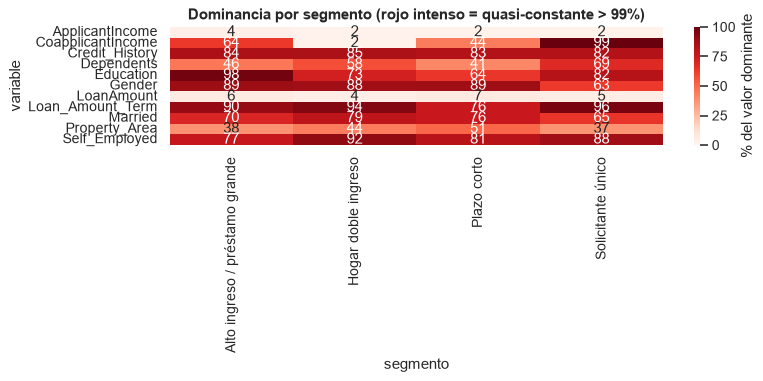

In [4]:
registros = []
for s in sorted(segmento.unique()):
    Xs = X.loc[segmento == s]
    for c in X.columns:
        d = diagnostico_columna(Xs[c])
        registros.append({"segmento": nombres_segmento[s], "variable": c,
                          "dominancia": d["dominancia"], "pct_nulos": d["pct_nulos"],
                          "cardinalidad": d["cardinalidad"],
                          "muerta": esta_muerta(d, dom_global[c])})
diag_seg = pd.DataFrame(registros)

# Heatmap de dominancia por segmento × variable
pivot_dom = diag_seg.pivot(index="variable", columns="segmento", values="dominancia")
fig, ax = plt.subplots(figsize=(9, max(4, 0.4 * len(X.columns))))
sns.heatmap(pivot_dom * 100, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% del valor dominante"}, ax=ax)
ax.set_title(f"Dominancia por segmento (rojo intenso = quasi-constante > {UMBRAL_DOMINANCIA:.0%})",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
# Variables muertas en ALGÚN segmento (aunque estén sanas globalmente)
muertas_por_seg = diag_seg[diag_seg["muerta"]]
print("Combinaciones (variable, segmento) donde la variable está MUERTA:")
if len(muertas_por_seg):
    print(muertas_por_seg[["variable", "segmento", "dominancia", "pct_nulos"]].to_string(index=False))
else:
    print("  ninguna — en este dataset todas las variables sobreviven en todos los segmentos.")
muertas_algun_seg = sorted(muertas_por_seg["variable"].unique())
print("\nVariables muertas en AL MENOS un segmento:", muertas_algun_seg if muertas_algun_seg else "ninguna")

Combinaciones (variable, segmento) donde la variable está MUERTA:
  ninguna — en este dataset todas las variables sobreviven en todos los segmentos.

Variables muertas en AL MENOS un segmento: ninguna


## 3.4 Demostración: por qué el diagnóstico por segmento atrapa lo que el global no ve

En este dataset (limpio, de enseñanza) puede que ninguna variable se descarte. Para que **veas el
mecanismo funcionando**, inyectamos una variable sintética `promo_flag` que vale 1 solo para
algunos clientes de un segmento y 0 en todos los demás — sana globalmente, muerta en 3 de 4
segmentos.

In [6]:
rng = np.random.default_rng(0)
seg_objetivo = sorted(segmento.unique())[0]
promo = pd.Series(0, index=X.index, name="promo_flag")
mask = segmento == seg_objetivo
promo.loc[mask] = rng.integers(0, 2, size=mask.sum())  # 0/1 solo en un segmento
X_demo = X.assign(promo_flag=promo)

dg = diagnostico_columna(X_demo["promo_flag"])
dom_g_promo = dg["dominancia"]
print(f"'promo_flag' — diagnóstico GLOBAL:")
print(f"  dominancia global: {dg['dominancia']:.1%}  → ¿muerta? {esta_muerta(dg, dom_g_promo)}")
print()
print("'promo_flag' — diagnóstico POR SEGMENTO (con filtro global):")
for s in sorted(segmento.unique()):
    d = diagnostico_columna(X_demo.loc[segmento == s, "promo_flag"])
    print(f"  {nombres_segmento[s]:32s} dominancia {d['dominancia']:.0%}  "
          f"→ ¿muerta? {esta_muerta(d, dom_g_promo)}")
print()
print(">> A diferencia de CoapplicantIncome, 'promo_flag' SÍ domina también a nivel global")
print(f"   ({dom_g_promo:.0%}): es constante en casi toda la cartera, no solo en un segmento.")
print("   Por eso el filtro global la deja caer — es ruido de verdad, no un cero significativo.")

'promo_flag' — diagnóstico GLOBAL:
  dominancia global: 75.6%  → ¿muerta? False

'promo_flag' — diagnóstico POR SEGMENTO (con filtro global):
  Hogar doble ingreso              dominancia 55%  → ¿muerta? False
  Alto ingreso / préstamo grande   dominancia 100%  → ¿muerta? True
  Solicitante único                dominancia 100%  → ¿muerta? True
  Plazo corto                      dominancia 100%  → ¿muerta? True

>> A diferencia de CoapplicantIncome, 'promo_flag' SÍ domina también a nivel global
   (76%): es constante en casi toda la cartera, no solo en un segmento.
   Por eso el filtro global la deja caer — es ruido de verdad, no un cero significativo.


## 3.5 VarianceThreshold: el filtro automático de sklearn

Para variables **numéricas**, `VarianceThreshold` elimina las de varianza por debajo de un umbral.
Es el equivalente automatizado de la regla de dominancia. Ojo: la varianza **tiene unidades**, así
que solo tiene sentido sobre datos comparables (aquí, las numéricas crudas).

In [7]:
from sklearn.feature_selection import VarianceThreshold
num = X.select_dtypes("number")
vt = VarianceThreshold(threshold=0.0).fit(num)  # elimina solo varianza EXACTAMENTE cero
sobreviven = num.columns[vt.get_support()].tolist()
eliminadas_vt = [c for c in num.columns if c not in sobreviven]
print("Numéricas con varianza cero (VarianceThreshold):", eliminadas_vt if eliminadas_vt else "ninguna")

Numéricas con varianza cero (VarianceThreshold): ninguna


## 3.6 Decisión final y esquema único

Consolidamos: una variable se descarta si está muerta **globalmente** o en **algún segmento** o
por varianza cero. El resultado es **un solo esquema** de columnas para train y test.

In [8]:
a_descartar = sorted(set(muertas_global) | set(muertas_algun_seg) | set(eliminadas_vt))

print("=" * 60)
print("DECISIÓN DE LIMPIEZA DURA")
print("=" * 60)
if a_descartar:
    for c in a_descartar:
        motivos = []
        if c in muertas_global: motivos.append("muerta global")
        if c in muertas_algun_seg: motivos.append("muerta en algún segmento")
        if c in eliminadas_vt: motivos.append("varianza cero")
        print(f"  ✗ {c}: {', '.join(motivos)}")
else:
    print("  ✓ Ninguna variable se descarta: todas superan los umbrales en todos los segmentos.")
    print("    (Es un dataset limpio de enseñanza. En datos reales de banca, con cientos de")
    print("     variables derivadas, esta etapa suele eliminar decenas.)")
print("=" * 60)

X_limpio = X.drop(columns=a_descartar)
print(f"\nColumnas: {X.shape[1]} → {X_limpio.shape[1]}  (descartadas: {len(a_descartar)})")

DECISIÓN DE LIMPIEZA DURA
  ✓ Ninguna variable se descarta: todas superan los umbrales en todos los segmentos.
    (Es un dataset limpio de enseñanza. En datos reales de banca, con cientos de
     variables derivadas, esta etapa suele eliminar decenas.)

Columnas: 11 → 11  (descartadas: 0)


## 3.7 Exportación

In [9]:
cols_finales = X_limpio.columns.tolist()
# aplicamos el MISMO esquema a train y test (+ metadatos)
train_out = train[cols_finales + [SEGMENT_COL, TARGET]]
test_out = test[cols_finales + [SEGMENT_COL, TARGET]]

save_stage(train_out, "03_train")
save_stage(test_out, "03_test")

reporte = {
    "columnas_descartadas": a_descartar,
    "columnas_conservadas": cols_finales,
    "umbrales": {"nulos": UMBRAL_NULOS, "dominancia": UMBRAL_DOMINANCIA,
                 "cardinalidad": UMBRAL_CARDINALIDAD},
    "muertas_global": muertas_global,
    "muertas_algun_segmento": muertas_algun_seg,
}
save_report(reporte, "columnas_descartadas")
save_table(diag_global, "limpieza_diagnostico_global")
save_table(diag_seg.pivot(index="variable", columns="segmento", values="dominancia").round(3),
           "limpieza_dominancia_por_segmento")

print(f"03_train → {train_out.shape} | 03_test → {test_out.shape}")
print("Reportes → columnas_descartadas.json + limpieza_*.csv")

03_train → (491, 13) | 03_test → (123, 13)
Reportes → columnas_descartadas.json + limpieza_*.csv


## 🔍 Lectura analítica de la limpieza

El valor de esta etapa no es cuántas columnas cayeron, sino **entender la estructura de la
cartera** que el diagnóstico por segmento revela.

In [10]:
print("LO QUE REVELA EL DIAGNÓSTICO POR SEGMENTO")
print("=" * 66)
print(f"Columnas: {X.shape[1]} → {X_limpio.shape[1]}  (descartadas: {len(a_descartar)})")
print()
# variables quasi-constantes DENTRO de algún segmento (aunque no se descarten)
casi_muertas = diag_seg[(diag_seg["dominancia"] > 0.95) & (~diag_seg["muerta"])]
if len(casi_muertas):
    print("Variables muy homogéneas en algún segmento (señal de estructura, NO se descartan):")
    for _, r in casi_muertas.sort_values("dominancia", ascending=False).head(5).iterrows():
        print(f"   · {r['variable']:18s} en '{r['segmento']}': {r['dominancia']:.0%} un solo valor")
    print()
    print(">> Esto NO es ruido: es que el segmento se define por ese valor.")
    print("   Ej.: CoapplicantIncome≈0 en 'Solicitante único' — el 0 ES el segmento.")
    print("   Por eso el filtro global la rescata: es un 'cero significativo', no varianza muerta.")
else:
    print("Ninguna variable es quasi-constante dentro de un segmento.")
print("=" * 66)
print()
print("Siguiente paso → 04_outliers_mv.ipynb")

LO QUE REVELA EL DIAGNÓSTICO POR SEGMENTO
Columnas: 11 → 11  (descartadas: 0)

Variables muy homogéneas en algún segmento (señal de estructura, NO se descartan):
   · CoapplicantIncome  en 'Solicitante único': 99% un solo valor
   · Education          en 'Alto ingreso / préstamo grande': 98% un solo valor
   · Loan_Amount_Term   en 'Solicitante único': 96% un solo valor

>> Esto NO es ruido: es que el segmento se define por ese valor.
   Ej.: CoapplicantIncome≈0 en 'Solicitante único' — el 0 ES el segmento.
   Por eso el filtro global la rescata: es un 'cero significativo', no varianza muerta.

Siguiente paso → 04_outliers_mv.ipynb
